In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../src")   # para importar el paquete fraud desde el notebook

import pandas as pd
from fraud.data import load_baf, TARGET, MONTH
import numpy as np

df = load_baf("../data/raw/Base.csv")
print(df.shape)
print(list(df.columns))
df[TARGET].value_counts(normalize=True)

(1000000, 32)
['fraud_bool', 'income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'customer_age', 'days_since_request', 'intended_balcon_amount', 'payment_type', 'zip_count_4w', 'velocity_6h', 'velocity_24h', 'velocity_4w', 'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w', 'employment_status', 'credit_risk_score', 'email_is_free', 'housing_status', 'phone_home_valid', 'phone_mobile_valid', 'bank_months_count', 'has_other_cards', 'proposed_credit_limit', 'foreign_request', 'source', 'session_length_in_minutes', 'device_os', 'keep_alive_session', 'device_distinct_emails_8w', 'device_fraud_count', 'month']


fraud_bool
0    0.988971
1    0.011029
Name: proportion, dtype: float64

In [2]:
print(df.shape, df.columns)

(1000000, 32) Index(['fraud_bool', 'income', 'name_email_similarity',
       'prev_address_months_count', 'current_address_months_count',
       'customer_age', 'days_since_request', 'intended_balcon_amount',
       'payment_type', 'zip_count_4w', 'velocity_6h', 'velocity_24h',
       'velocity_4w', 'bank_branch_count_8w',
       'date_of_birth_distinct_emails_4w', 'employment_status',
       'credit_risk_score', 'email_is_free', 'housing_status',
       'phone_home_valid', 'phone_mobile_valid', 'bank_months_count',
       'has_other_cards', 'proposed_credit_limit', 'foreign_request', 'source',
       'session_length_in_minutes', 'device_os', 'keep_alive_session',
       'device_distinct_emails_8w', 'device_fraud_count', 'month'],
      dtype='str')


### Tasa de fraude global y por mes

In [3]:
print("TASA DE FRAUDE GLOBAL: ", df[TARGET].mean())
por_mes = df.groupby("month")[TARGET].agg(filas="size", fraudes="sum", tasa="mean")
por_mes 

TASA DE FRAUDE GLOBAL:  0.011029


,filas,fraudes,tasa
month,,,
0,132440,1500,0.011326
1,127620,1198,0.009387
2,136979,1198,0.008746
3,150936,1392,0.009222
4,127691,1452,0.011371
5,119323,1411,0.011825
6,108168,1450,0.013405
7,96843,1428,0.014746


### TIpos de datos y columnas constantes

In [4]:
print(df.dtypes.value_counts())
print("Columnas con 1 solo valor:", [c for c in df.columns if df[c].nunique() == 1])

int64      18
float64     9
str         5
Name: count, dtype: int64
Columnas con 1 solo valor: ['device_fraud_count']


### Valores faltantes escondidos

In [5]:
num = df.select_dtypes("number").drop(columns=[TARGET, "month"])
neg = (num < 0).sum()
neg[neg > 0].sort_values(ascending=False)

intended_balcon_amount          742523
prev_address_months_count       712920
bank_months_count               253635
credit_risk_score                14445
current_address_months_count      4254
session_length_in_minutes         2015
device_distinct_emails_8w          359
velocity_6h                         44
dtype: int64

### Fraude por grupos (Edades, estado de empleo y estado de vivienda)

In [6]:
for col in ["customer_age", "employment_status", "housing_status", "payment_type", "source"]:
    print(df.groupby(col)[TARGET].agg(filas="size", tasa="mean").round(4), "\n")

               filas    tasa
customer_age                
10             20987  0.0035
20            245855  0.0049
30            311433  0.0083
40            238712  0.0120
50            140353  0.0200
60             34770  0.0330
70              6517  0.0404
80              1297  0.0493
90                76  0.0526 

                    filas    tasa
employment_status                
CA                 730252  0.0122
CB                 138288  0.0069
CC                  37758  0.0247
CD                  26522  0.0038
CE                  22693  0.0023
CF                  44034  0.0019
CG                    453  0.0155 

                 filas    tasa
housing_status                
BA              169675  0.0375
BB              260965  0.0060
BC              372143  0.0061
BD               26161  0.0086
BE              169135  0.0034
BF                1669  0.0042
BG                 252  0.0040 

               filas    tasa
payment_type                
AA            258249  0.0053
AB 

In [7]:
for c in ["prev_address_months_count", "current_address_months_count", "bank_months_count",
          "session_length_in_minutes", "device_distinct_emails_8w", "velocity_6h", "credit_risk_score"]:
    print(c, df.loc[df[c] < 0, c].value_counts().head(3).to_dict())

prev_address_months_count {-1: 712920}
current_address_months_count {-1: 4254}
bank_months_count {-1: 253635}
session_length_in_minutes {-1.0: 2015}
device_distinct_emails_8w {-1: 359}
velocity_6h {-29.235882651923703: 1, -80.69066966650415: 1, -130.45692803910583: 1}
credit_risk_score {-1: 488, -2: 473, -3: 440}


In [8]:
import lightgbm as lgb
from fraud.data import temporal_split
from fraud.metrics import ks_statistic, gini, psi

for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].astype("category")

train, valid, test = temporal_split(df)
feats = [c for c in df.columns if c not in (TARGET, MONTH)]   # month NO es variable

model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)
model.fit(train[feats], train[TARGET])

s_tr = model.predict_proba(train[feats])[:, 1]
s_va = model.predict_proba(valid[feats])[:, 1]
print("KS valid:", ks_statistic(valid[TARGET], s_va))
print("Gini valid:", gini(valid[TARGET], s_va))
print("PSI score train->valid:", psi(s_tr, s_va))

KS valid: 0.6245465272447412
Gini valid: 0.7874894652904312
PSI score train->valid: 0.004771973063573655


In [9]:
imp = pd.Series(model.booster_.feature_importance("gain"), index=feats).sort_values(ascending=False)
print((imp / imp.sum()).head(10).round(3))

housing_status                  0.168
device_os                       0.080
name_email_similarity           0.057
current_address_months_count    0.054
credit_risk_score               0.052
bank_branch_count_8w            0.040
intended_balcon_amount          0.037
days_since_request              0.036
velocity_4w                     0.035
has_other_cards                 0.035
dtype: float64


In [10]:
from fraud.metrics import recall_at_fpr
print("Recall @ 5% FPR (valid):", recall_at_fpr(valid[TARGET], s_va))

Recall @ 5% FPR (valid): 0.5393338058114813


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from fraud.data import clean


dfc = clean(df)
train_c, valid_c, _ = temporal_split(dfc)
cat_cols = dfc[feats].select_dtypes("category").columns.tolist()
num_cols = [c for c in feats if c not in cat_cols]

pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
modelos = {
    "Regresion logistica": make_pipeline(pre, LogisticRegression(max_iter=1000)),
    "LightGBM": lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1),
}
filas = []
for nombre, m in modelos.items():
    m.fit(train_c[feats], train_c[TARGET])
    s = m.predict_proba(valid_c[feats])[:, 1]
    filas.append({"modelo": nombre,
                  "KS": ks_statistic(valid_c[TARGET], s),
                  "Gini": gini(valid_c[TARGET], s),
                  "Recall@5%FPR": recall_at_fpr(valid_c[TARGET], s),
                  "Recall@1%FPR": recall_at_fpr(valid_c[TARGET], s, 0.01)})
pd.DataFrame(filas).round(3)

,modelo,KS,Gini,Recall@5%FPR,Recall@1%FPR
0,Regresion logistica,0.604,0.766,0.509,0.247
1,LightGBM,0.627,0.787,0.534,0.279


                              level_0                           level_1  \
344                 credit_risk_score             proposed_credit_limit   
235                      velocity_24h                       velocity_4w   
209                       velocity_6h                      velocity_24h   
112                      customer_age  date_of_birth_distinct_emails_4w   
210                       velocity_6h                       velocity_4w   
185                      zip_count_4w                       velocity_4w   
391                  phone_home_valid                phone_mobile_valid   
262                       velocity_4w  date_of_birth_distinct_emails_4w   
184                      zip_count_4w                      velocity_24h   
115                      customer_age                  phone_home_valid   
87       current_address_months_count  date_of_birth_distinct_emails_4w   
263                       velocity_4w                 credit_risk_score   
315  date_of_birth_distin

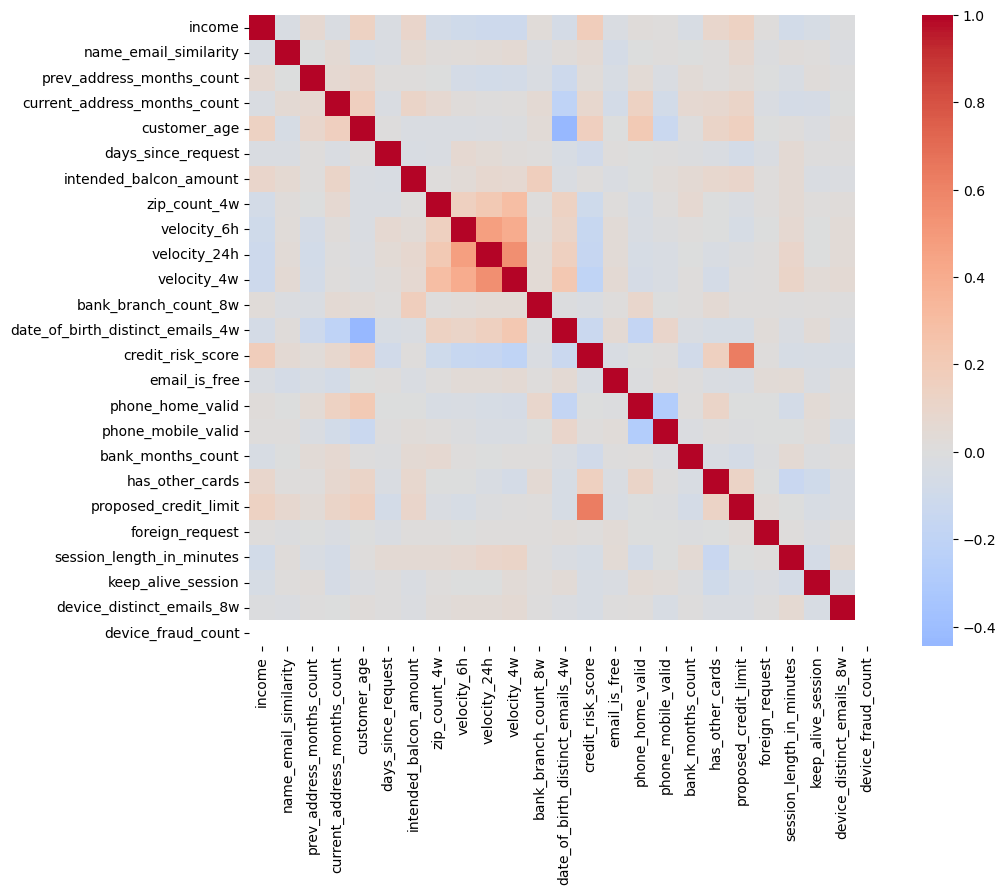

In [12]:
import numpy as np, seaborn as sns, matplotlib.pyplot as plt

muestra = dfc[num_cols].sample(200_000, random_state=42)
corr = muestra.corr(method="spearman")

pares = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
         .stack().rename("rho").reset_index())
pares["abs"] = pares["rho"].abs()
print(pares.sort_values("abs", ascending=False).head(15).round(3))

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True)
plt.tight_layout()
plt.savefig("../reports/figures/correlaciones.png", dpi=150)

In [13]:
from sklearn.metrics import roc_auc_score

aucs = {c: roc_auc_score(train_c[TARGET], train_c[c].fillna(train_c[c].median())) for c in num_cols}
fuerza = (pd.Series(aucs) - 0.5).abs().sort_values(ascending=False)
print(fuerza.head(15).round(3))

customer_age                        0.166
credit_risk_score                   0.160
current_address_months_count        0.141
proposed_credit_limit               0.139
date_of_birth_distinct_emails_4w    0.133
income                              0.132
keep_alive_session                  0.121
name_email_similarity               0.099
bank_branch_count_8w                0.087
phone_home_valid                    0.071
has_other_cards                     0.066
email_is_free                       0.063
intended_balcon_amount              0.050
bank_months_count                   0.047
days_since_request                  0.037
dtype: float64


In [14]:
df["income"].value_counts()

income
0.9    221419
0.1    157449
0.8    146650
0.6    111973
0.7    105109
0.4     81364
0.2     69345
0.5     55858
0.3     50833
Name: count, dtype: int64

In [15]:
from sklearn.preprocessing import SplineTransformer
from fraud.features import add_features

dfe = add_features(dfc)
nuevas = ["limit_to_income", "vel_6h_vs_24h", "vel_24h_vs_4w",
          "balcon_negativo", "sin_direccion_previa", "sin_cuenta_previa"]
num_e = num_cols + nuevas
spl_cols = ["customer_age", "credit_risk_score", "current_address_months_count",
            "proposed_credit_limit", "name_email_similarity"]   # sin income
feats_e = feats + nuevas + ["income_band"]
cat_e = cat_cols + ["income_band"]
train_e, valid_e, _ = temporal_split(dfe)

def hacer_lr(numericas, categoricas, splines=()):
    resto = [c for c in numericas if c not in splines]
    partes = [("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                    StandardScaler()), resto),
              ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)]
    if splines:
        partes.append(("spl", make_pipeline(SimpleImputer(strategy="median"),
                                            SplineTransformer(n_knots=5, degree=3)), list(splines)))
    return make_pipeline(ColumnTransformer(partes), LogisticRegression(max_iter=2000))

def evaluar(nombre, modelo, tr, va, cols):
    modelo.fit(tr[cols], tr[TARGET])
    s = modelo.predict_proba(va[cols])[:, 1]
    return {"modelo": nombre, "KS": ks_statistic(va[TARGET], s), "Gini": gini(va[TARGET], s),
            "Recall@5%FPR": recall_at_fpr(va[TARGET], s),
            "Recall@1%FPR": recall_at_fpr(va[TARGET], s, 0.01)}

lgbm = lambda: lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)
filas = [
    evaluar("LR base", hacer_lr(num_cols, cat_cols), train_c, valid_c, feats),
    evaluar("LR + features", hacer_lr(num_e, cat_e), train_e, valid_e, feats_e),
    evaluar("LR + features + splines", hacer_lr(num_e, cat_e, spl_cols), train_e, valid_e, feats_e),
    evaluar("LightGBM base", lgbm(), train_c, valid_c, feats),
    evaluar("LightGBM + features", lgbm(), train_e, valid_e, feats_e),
]
pd.DataFrame(filas).round(3)

KeyError: "['limit_to_income'] not in index"